# Fake Job Posting Detection System
### An AI-powered application to identify potentially fraudulent job advertisements.

## About the Project

Finding a genuine job opportunity online is not always easy. Many job seekers encounter fraudulent job advertisements that look legitimate but are designed to deceive applicants.

These advertisements may contain misleading salary offers, unrealistic job requirements, suspicious company information, or requests for sensitive personal details.

The **Fake Job Posting Detection System** is a Machine Learning-powered application that helps users identify potentially fraudulent job advertisements before applying.

Users can submit job posting information, such as the job title, company profile, description, requirements, and other relevant details. The system analyzes this information using a trained Machine Learning model and predicts whether the advertisement is likely to be genuine or potentially fraudulent.

## How Does It Help Users?

The application aims to:

- Help job seekers identify suspicious job advertisements.
- Reduce the risk of falling for employment scams.
- Analyze job descriptions and company information automatically.
- Provide quick predictions without manually investigating every advertisement.
- Encourage users to verify suspicious opportunities before sharing personal information or making payments.

## How to Use the Application?

1. Open the Fake Job Posting Detection application.
2. Enter or paste the details of a job advertisement.
3. Submit the information for analysis.
4. The Machine Learning model analyzes the submitted details.
5. View the prediction.

## What Does the Application Show?

The application provides one of two possible classifications:

**Genuine Job Posting**

The submitted advertisement has characteristics more commonly associated with legitimate job postings.

**Potentially Fraudulent Job Posting**

The submitted advertisement contains patterns associated with fraudulent job postings and should be investigated further.

## Who Can Benefit From This Project?

- **Job Seekers:** To evaluate suspicious job advertisements before applying.
- **Fresh Graduates:** To become more cautious while searching for their first job.
- **Recruitment Platforms:** As a potential additional screening mechanism.
- **Career Guidance Communities:** To educate applicants about employment scams.

## Project Highlights

- Automated job advertisement analysis.
- Natural Language Processing for textual information.
- Machine Learning-based classification.
- Fast prediction through an API.
- Simple and user-friendly interface.

## Important Disclaimer

This application provides predictions based on patterns learned from historical job advertisement data. It does not guarantee that a job posting is genuine or fraudulent.

A genuine advertisement may occasionally be flagged as suspicious, and a fraudulent advertisement may go undetected.

Users should independently verify employers, company websites, contact details, and recruitment processes before sharing sensitive information or making payments.

---

**The Goal:** Make online job searching safer by using Machine Learning to help people recognize potentially fraudulent employment opportunities.

Raw Data
    ↓
Cleaning
    ↓
Text Preparation + Feature Engineering
    ↓
X and y
    ↓
Train-Test Split
    ↓
TF-IDF + Scaling
    ↓
Model
    ↓
Prediction
    ↓
Evaluation

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import re

In [2]:
data = pd.read_csv(r"C:\Users\rohit\Downloads\AI and Data Science\𝗙𝗮𝘀𝘁𝗔𝗣𝗜\learning project\models and data\data\fake_job_postings.csv")

df = pd.DataFrame(data)

df

,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0
3,4,Account Executive - Washington DC,"US, DC, Washington",Sales,NaN,Our passion for improving quality of life thro...,THE COMPANY: ESRI – Environmental Systems Rese...,"EDUCATION: Bachelor’s or Master’s in GIS, busi...",Our culture is anything but corporate—we have ...,0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0
4,5,Bill Review Manager,"US, FL, Fort Worth",NaN,NaN,SpotSource Solutions LLC is a Global Human Cap...,JOB TITLE: Itemization Review ManagerLOCATION:...,QUALIFICATIONS:RN license in the State of Texa...,Full Benefits Offered,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17875,17876,Account Director - Distribution,"CA, ON, Toronto",Sales,NaN,Vend is looking for some awesome new talent to...,Just in case this is the first time you’ve vis...,To ace this role you:Will eat comprehensive St...,What can you expect from us?We have an open cu...,0,1,1,Full-time,Mid-Senior level,NaN,Computer Software,Sales,0
17876,17877,Payroll Accountant,"US, PA, Philadelphia",Accounting,NaN,WebLinc is the e-commerce platform and service...,The Payroll Accountant will focus primarily on...,- B.A. or B.S. in Accounting- Desire to have f...,Health &amp; WellnessMedical planPrescription ...,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Internet,Accounting/Auditing,0
17877,17878,Project Cost Control Staff Engineer - Cost Con...,"US, TX, Houston",NaN,NaN,We Provide Full Time Permanent Positions for m...,Experienced Project Cost Control Staff Enginee...,At least 12 years professional experience.Abil...,NaN,0,0,0,Full-time,NaN,NaN,NaN,NaN,0
17878,17879,Graphic Designer,"NG, LA, Lagos",NaN,NaN,NaN,Nemsia Studios is looking for an experienced v...,1. Must be fluent in the latest versions of Co...,Competitive salary (compensation will be based...,0,0,1,Contract,Not Applicable,Professional,Graphic Design,Design,0


In [3]:
df.columns

Index(['job_id', 'title', 'location', 'department', 'salary_range',
       'company_profile', 'description', 'requirements', 'benefits',
       'telecommuting', 'has_company_logo', 'has_questions', 'employment_type',
       'required_experience', 'required_education', 'industry', 'function',
       'fraudulent'],
      dtype='str')

In [ ]:
print("Columns:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
display(df.info())

print("\nMissing values (top 20):")
display(df.isna().sum().sort_values(ascending=False).head(20))

print("\nDuplicate rows:", df.duplicated().sum())


print("\nTarget distribution:")
display(df["fraudulent"].value_counts(dropna=False).rename(index={0: "Genuine (0)", 1: "Fraudulent (1)"}))

Columns:
['job_id', 'title', 'location', 'department', 'salary_range', 'company_profile', 'description', 'requirements', 'benefits', 'telecommuting', 'has_company_logo', 'has_questions', 'employment_type', 'required_experience', 'required_education', 'industry', 'function', 'fraudulent']

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 17880 entries, 0 to 17879
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   job_id               17880 non-null  int64
 1   title                17880 non-null  str  
 2   location             17534 non-null  str  
 3   department           6333 non-null   str  
 4   salary_range         2868 non-null   str  
 5   company_profile      14572 non-null  str  
 6   description          17879 non-null  str  
 7   requirements         15184 non-null  str  
 8   benefits             10668 non-null  str  
 9   telecommuting        17880 non-null  int64
 10 

None


Missing values (top 20):


salary_range           15012
department             11547
required_education      8105
benefits                7212
required_experience     7050
function                6455
industry                4903
employment_type         3471
company_profile         3308
requirements            2696
location                 346
description                1
title                      0
job_id                     0
telecommuting              0
has_questions              0
has_company_logo           0
fraudulent                 0
dtype: int64


Duplicate rows: 0

Target distribution:


fraudulent
Genuine (0)       17014
Fraudulent (1)      866
Name: count, dtype: int64

In [5]:
# data cleaning

print(df.isnull().sum())

print(df.duplicated().sum())

job_id                     0
title                      0
location                 346
department             11547
salary_range           15012
company_profile         3308
description                1
requirements            2696
benefits                7212
telecommuting              0
has_company_logo           0
has_questions              0
employment_type         3471
required_experience     7050
required_education      8105
industry                4903
function                6455
fraudulent                 0
dtype: int64
0


In [6]:
# lets clean the data

# text columns - empty text is itself a signal, so fill with blank instead of dropping rows
text_cols = ['title', 'company_profile', 'description', 'requirements', 'benefits']

for col in text_cols:
    df[col] = df[col].fillna('')

# category columns - fill with Unknown (used for graphs only)
cat_cols = ['employment_type', 'required_experience', 'required_education', 'industry', 'function', 'department']

for col in cat_cols:
    df[col] = df[col].fillna('Unknown')

df['location'] = df['location'].fillna('Unknown')

# salary_range is 84% empty so we only keep "is it given or not"
df['has_salary'] = df['salary_range'].notnull().astype(int)

df.isnull().sum()

job_id                     0
title                      0
location                   0
department                 0
salary_range           15012
company_profile            0
description                0
requirements               0
benefits                   0
telecommuting              0
has_company_logo           0
has_questions              0
employment_type            0
required_experience        0
required_education         0
industry                   0
function                   0
fraudulent                 0
has_salary                 0
dtype: int64

In [7]:
# data cleaned now

df.duplicated().sum()

df.drop_duplicates(inplace=True)

df['fraudulent'].value_counts()

fraudulent
0    17014
1      866
Name: count, dtype: int64

In [8]:
# folder to save all graphs

graphs_path = "Graphs Used"
os.makedirs(graphs_path, exist_ok=True)

sns.set_theme(style="whitegrid")

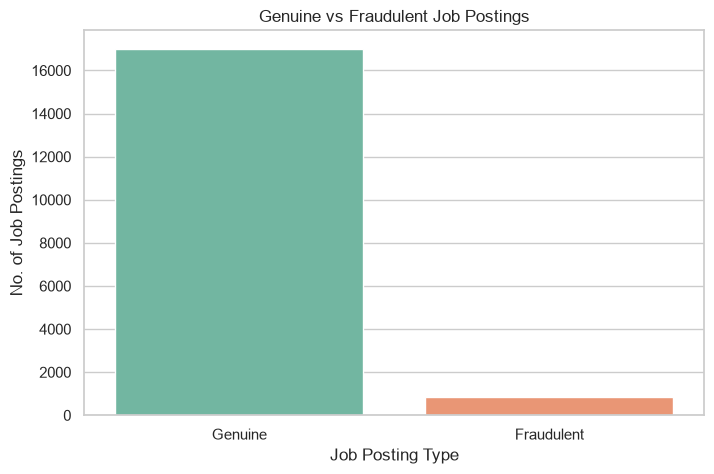

Fraudulent postings: 4.84%


In [9]:
# understand the dataset

# how imbalanced is the data?

plt.figure(figsize=(8, 5))

label_map = df['fraudulent'].map({0: 'Genuine', 1: 'Fraudulent'})

sns.countplot(x=label_map, hue=label_map, palette='Set2', legend=False)

plt.title("Genuine vs Fraudulent Job Postings")
plt.xlabel("Job Posting Type")
plt.ylabel("No. of Job Postings")

plt.savefig(os.path.join(graphs_path, "Class_Distribution.png"), dpi=300, bbox_inches="tight")

plt.show()

print(f"Fraudulent postings: {df['fraudulent'].mean() * 100:.2f}%")

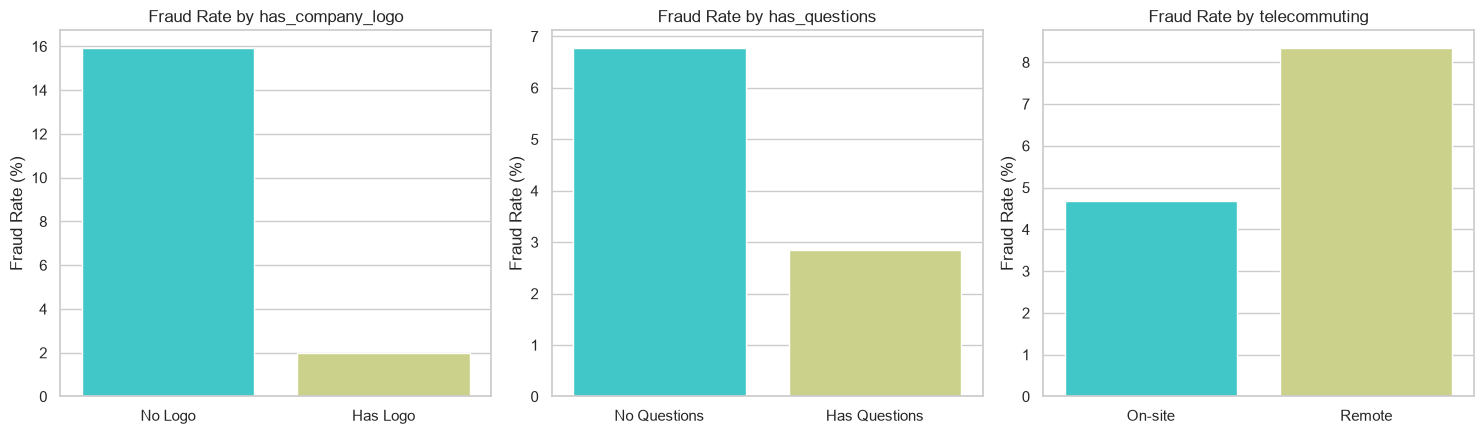

In [10]:
# do fake postings skip the company logo / screening questions?

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, col, names in zip(axes,
                          ['has_company_logo', 'has_questions', 'telecommuting'],
                          [['No Logo', 'Has Logo'], ['No Questions', 'Has Questions'], ['On-site', 'Remote']]):

    rate = df.groupby(col)['fraudulent'].mean() * 100
    sns.barplot(x=[names[i] for i in rate.index], y=rate.values, hue=[names[i] for i in rate.index],
                palette='rainbow', legend=False, ax=ax)
    ax.set_title(f"Fraud Rate by {col}")
    ax.set_xlabel("")
    ax.set_ylabel("Fraud Rate (%)")

plt.tight_layout()

plt.savefig(os.path.join(graphs_path, "Fraud_Rate_Binary_Features.png"), dpi=300, bbox_inches="tight")

plt.show()

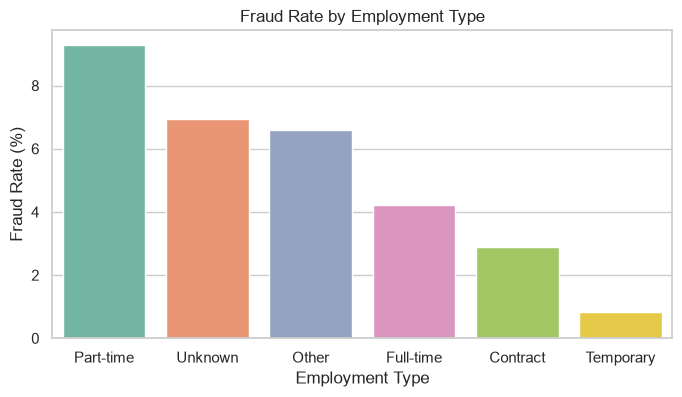

In [11]:
# which employment type has the most fraud?

final = (df.groupby('employment_type')['fraudulent'].mean() * 100).sort_values(ascending=False)

plt.figure(figsize=(8, 4))
sns.barplot(x=final.index, y=final.values, hue=final.index, palette='Set2', legend=False)

plt.title("Fraud Rate by Employment Type")
plt.xlabel("Employment Type")
plt.ylabel("Fraud Rate (%)")

plt.savefig(os.path.join(graphs_path, "Employment_Type_Fraud_Rate.png"), dpi=300, bbox_inches="tight")

plt.show()

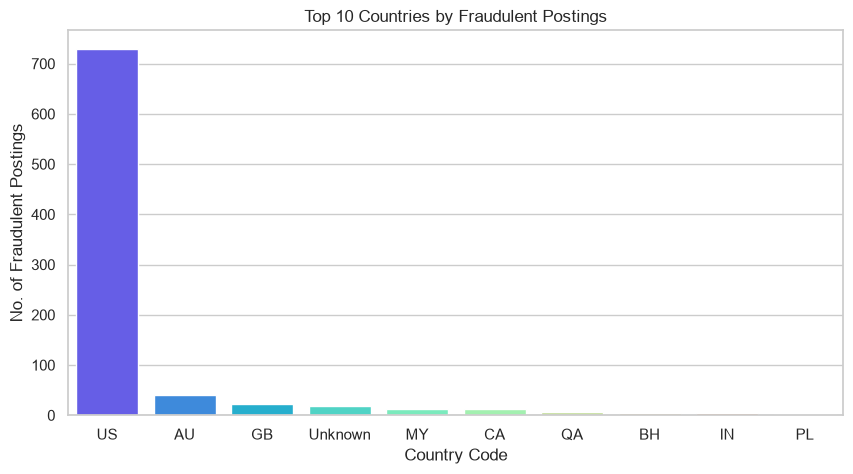

In [12]:
# which countries have the most fraudulent postings?

df['country'] = df['location'].str.split(',').str[0].str.strip()

top_countries = df[df['fraudulent'] == 1]['country'].value_counts().head(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=top_countries.index, y=top_countries.values, hue=top_countries.index, palette='rainbow', legend=False)

plt.title("Top 10 Countries by Fraudulent Postings")
plt.xlabel("Country Code")
plt.ylabel("No. of Fraudulent Postings")

plt.savefig(os.path.join(graphs_path, "Top_Fraud_Countries.png"), dpi=300, bbox_inches="tight")

plt.show()

In [13]:
# text preparation

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'<[^>]+>', ' ', text)            # html tags
    text = re.sub(r'&[a-z]+;', ' ', text)           # html entities like &amp;
    text = re.sub(r'http\S+|www\.\S+', ' url ', text)
    text = re.sub(r'[^a-z0-9\s]', ' ', text)        # special characters
    text = re.sub(r'\s+', ' ', text).strip()
    return text

# one single text column = title + company profile + description + requirements + benefits
df['text'] = (df['title'] + ' ' + df['company_profile'] + ' ' + df['description'] + ' '
              + df['requirements'] + ' ' + df['benefits']).apply(clean_text)

df['text'].sample(2, random_state=1).values

<ArrowStringArray>
['jr business analyst quality analyst entry level duration full time w2location piscataway njjob description ba qa we are looking to hire resources for our financial health care clients candidate should have knowledge or experience in ba process qa testing junior or entry level candidates with ba qa skills are encouraged to apply candidates qualification masters degree in computer science engineering or similar field knowledge of ba and qa knowledge of databases like oracle and sql excellent communication skills must have a positive attitude if interested please send me updated resume with below details full name email id phone alternate phone current location address relocation preference availability visa status expected rate salary please send your visa scan copy along with above details so that i will forward your resume along with these details visa copy to my hr team they will contact with you sortrly please feel free to call me at phone 6fb4e3f0d879fbd771e07d2

In [14]:
# feature engineering - simple structured signals

df['has_company_profile'] = (df['company_profile'].str.strip() != '').astype(int)
df['has_requirements'] = (df['requirements'].str.strip() != '').astype(int)
df['has_benefits'] = (df['benefits'].str.strip() != '').astype(int)
df['text_length'] = df['text'].str.split().str.len()

df[['has_salary', 'has_company_profile', 'has_requirements', 'has_benefits', 'text_length']].describe()

,has_salary,has_company_profile,has_requirements,has_benefits,text_length
count,17880.000000,17880.000000,17880.000000,17880.000000,17880.000000
mean,0.160403,0.814989,0.849105,0.596197,391.149609
std,0.366989,0.388317,0.357956,0.490673,218.637291
min,0.000000,0.000000,0.000000,0.000000,2.000000
25%,0.000000,1.000000,1.000000,0.000000,236.000000
50%,0.000000,1.000000,1.000000,1.000000,365.000000
75%,0.000000,1.000000,1.000000,1.000000,513.000000
max,1.000000,1.000000,1.000000,1.000000,2191.000000


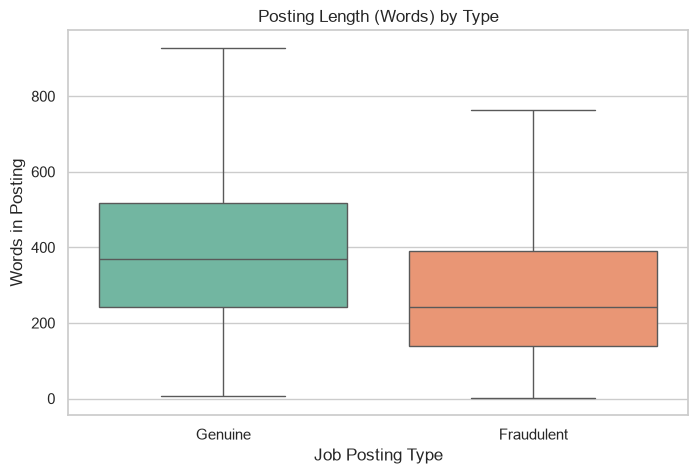

In [15]:
# do fake postings write shorter / longer ads?

plt.figure(figsize=(8, 5))

sns.boxplot(x=label_map.loc[df.index], y=df['text_length'], hue=label_map.loc[df.index], palette='Set2', legend=False,
            showfliers=False)

plt.title("Posting Length (Words) by Type")
plt.xlabel("Job Posting Type")
plt.ylabel("Words in Posting")

plt.savefig(os.path.join(graphs_path, "Text_Length_Comparison.png"), dpi=300, bbox_inches="tight")

plt.show()

In [16]:
# now providing features and target to model

num_cols = ['telecommuting', 'has_company_logo', 'has_questions', 'has_salary',
            'has_company_profile', 'has_requirements', 'has_benefits', 'text_length']

X = df[['text'] + num_cols]

y = df['fraudulent']

X.shape, y.shape

((17880, 9), (17880,))

In [17]:
# now next step is Test-Train Split

from sklearn.model_selection import train_test_split

# stratify = keeps same fraud % in train and test (data is highly imbalanced)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Train fraud %:", round(y_train.mean() * 100, 2))
print("Test fraud %:", round(y_test.mean() * 100, 2))

Train fraud %: 4.84
Test fraud %: 4.84


In [18]:
# now convert text to numbers (TF-IDF) and scale the numeric features

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from scipy.sparse import hstack, csr_matrix

tfidf = TfidfVectorizer(max_features=10000, stop_words='english', ngram_range=(1, 2), min_df=3)

X_train_text = tfidf.fit_transform(X_train['text'])
X_test_text = tfidf.transform(X_test['text'])

scaler = StandardScaler()

X_train_num = scaler.fit_transform(X_train[num_cols])
X_test_num = scaler.transform(X_test[num_cols])

# join text features + numeric features
X_train_final = hstack([X_train_text, csr_matrix(X_train_num)]).tocsr()
X_test_final = hstack([X_test_text, csr_matrix(X_test_num)]).tocsr()

X_train_final.shape, X_test_final.shape

((14304, 10008), (3576, 10008))

In [19]:
# scaling done now model building

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# class_weight = balanced because only ~5% postings are fraudulent
models = {
    "Logistic Regression": LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, class_weight='balanced_subsample', n_jobs=-1, random_state=42)
}

for name, m in models.items():
    m.fit(X_train_final, y_train)
    print(f"{name} trained")

Logistic Regression trained
Random Forest trained


In [20]:
# model building done now Evaluation

# accuracy alone is useless here (predicting everything genuine gives ~95%), so we use Precision / Recall / F1 / ROC-AUC

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

results = []

for name, m in models.items():
    pred = m.predict(X_test_final)
    prob = m.predict_proba(X_test_final)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision (Fraud)": precision_score(y_test, pred),
        "Recall (Fraud)": recall_score(y_test, pred),
        "F1 (Fraud)": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob)
    })

results = pd.DataFrame(results).set_index("Model").round(4)

results

,Accuracy,Precision (Fraud),Recall (Fraud),F1 (Fraud),ROC-AUC
Model,,,,,
Logistic Regression,0.9583,0.5426,0.8844,0.6725,0.9897
Random Forest,0.9804,1.0000,0.5954,0.7464,0.9904


In [21]:
# best model = highest F1 on the fraud class

best_name = results['F1 (Fraud)'].idxmax()

model = models[best_name]

y_pred = model.predict(X_test_final)
y_prob = model.predict_proba(X_test_final)[:, 1]

print("Best Model:", best_name)

from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred, target_names=["Genuine", "Fraudulent"]))

Best Model: Random Forest
              precision    recall  f1-score   support

     Genuine       0.98      1.00      0.99      3403
  Fraudulent       1.00      0.60      0.75       173

    accuracy                           0.98      3576
   macro avg       0.99      0.80      0.87      3576
weighted avg       0.98      0.98      0.98      3576



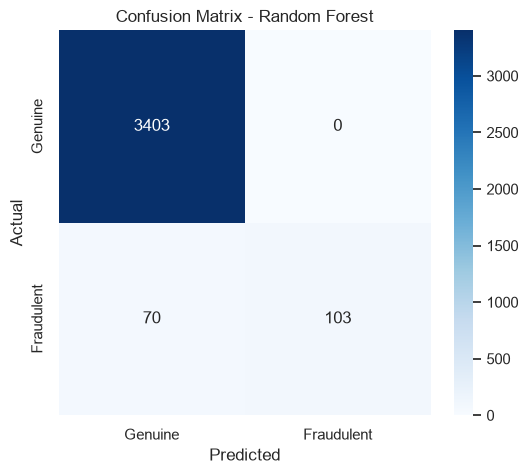

In [22]:
# confusion matrix

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Genuine', 'Fraudulent'], yticklabels=['Genuine', 'Fraudulent'])

plt.title(f"Confusion Matrix - {best_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.savefig(os.path.join(graphs_path, "Confusion_Matrix.png"), dpi=300, bbox_inches="tight")

plt.show()

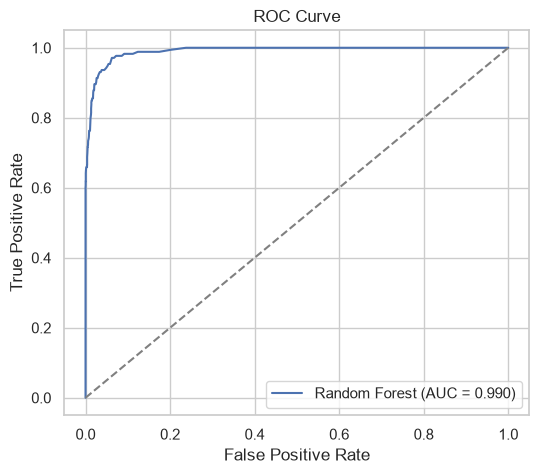

In [23]:
# ROC curve

from sklearn.metrics import roc_curve

fpr, tpr, _ = roc_curve(y_test, y_prob)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"{best_name} (AUC = {roc_auc_score(y_test, y_prob):.3f})")
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')

plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()

plt.savefig(os.path.join(graphs_path, "ROC_Curve.png"), dpi=300, bbox_inches="tight")

plt.show()

In [24]:
# evrything done

# now lets check actual vs predicted

final_data = {'Actual': y_test.values,
              'Predicted': y_pred,
              'Fraud Probability': y_prob.round(3)}

comparison = pd.DataFrame(final_data, index=y_test.index)

comparison.head(10)

,Actual,Predicted,Fraud Probability
16995,0,0,0.085
9357,0,0,0.005
11561,0,0,0.010
1105,0,0,0.000
1980,0,0,0.010
17264,0,0,0.000
13052,0,0,0.015
5549,0,0,0.015
9399,0,0,0.055
9333,0,0,0.015


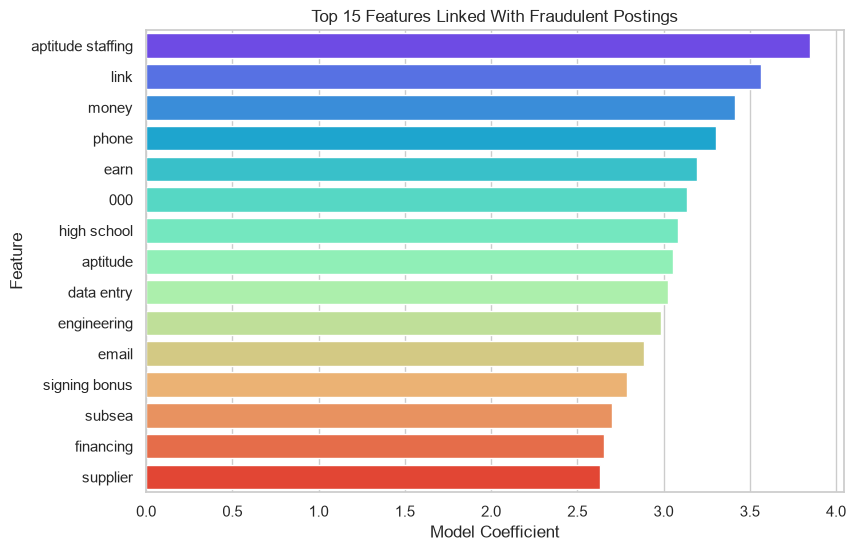

In [25]:
# what words does the model link with fraud? (from Logistic Regression coefficients)

lr = models["Logistic Regression"]

feature_names = np.array(list(tfidf.get_feature_names_out()) + num_cols)

coef = pd.Series(lr.coef_[0], index=feature_names)

top_fraud = coef.sort_values(ascending=False).head(15)

plt.figure(figsize=(9, 6))
sns.barplot(x=top_fraud.values, y=top_fraud.index, hue=top_fraud.index, palette='rainbow', legend=False)

plt.title("Top 15 Features Linked With Fraudulent Postings")
plt.xlabel("Model Coefficient")
plt.ylabel("Feature")

plt.savefig(os.path.join(graphs_path, "Top_Fraud_Features.png"), dpi=300, bbox_inches="tight")

plt.show()

In [26]:
# save everything so the API / app can load it later

import joblib

os.makedirs("model_files", exist_ok=True)

joblib.dump(model, "model_files/fake_job_model.pkl")
joblib.dump(tfidf, "model_files/tfidf_vectorizer.pkl")
joblib.dump(scaler, "model_files/scaler.pkl")
joblib.dump(num_cols, "model_files/num_cols.pkl")

print("Model files saved in /model_files")

Model files saved in /model_files


In [27]:
# now lets build system so that people can check their job posting too

def predict_job(title, company_profile, description, requirements, benefits,
                telecommuting, has_company_logo, has_questions, salary_range):

    text = clean_text(' '.join([title, company_profile, description, requirements, benefits]))

    user_data = pd.DataFrame([{
        'telecommuting': telecommuting,
        'has_company_logo': has_company_logo,
        'has_questions': has_questions,
        'has_salary': int(salary_range.strip() != ''),
        'has_company_profile': int(company_profile.strip() != ''),
        'has_requirements': int(requirements.strip() != ''),
        'has_benefits': int(benefits.strip() != ''),
        'text_length': len(text.split())
    }])[num_cols]

    user_text = tfidf.transform([text])
    user_num = scaler.transform(user_data)

    user_final = hstack([user_text, csr_matrix(user_num)]).tocsr()

    prob = model.predict_proba(user_final)[0][1]

    label = "Potentially Fraudulent Job Posting" if prob >= 0.5 else "Genuine Job Posting"

    return label, prob

In [28]:
# quick test with a suspicious looking posting

label, prob = predict_job(
    title="Work From Home Data Entry - Earn $5000 Weekly",
    company_profile="",
    description="No experience needed! Earn money from home. Send your bank details and a registration fee to get started immediately.",
    requirements="",
    benefits="",
    telecommuting=1,
    has_company_logo=0,
    has_questions=0,
    salary_range=""
)

print(f"{label} (fraud probability: {prob * 100:.1f}%)")

Potentially Fraudulent Job Posting (fraud probability: 71.5%)


In [ ]:
# user input

title = input("Enter Job Title: ")

company_profile = input("Enter Company Profile (leave blank if none): ")

description = input("Enter Job Description: ")

requirements = input("Enter Requirements (leave blank if none): ")

benefits = input("Enter Benefits (leave blank if none): ")

salary_range = input("Enter Salary Range (leave blank if none): ")

telecommuting = int(input("Is it a remote job? (1 = Yes, 0 = No): "))

has_company_logo = int(input("Does the posting have a company logo? (1 = Yes, 0 = No): "))

has_questions = int(input("Does the posting have screening questions? (1 = Yes, 0 = No): "))

label, prob = predict_job(title, company_profile, description, requirements, benefits,
                          telecommuting, has_company_logo, has_questions, salary_range)

print(f"\nResult: {label}")
print(f"Fraud Probability: {prob * 100:.1f}%")
print("\nNote: This is only a prediction. Always verify the employer before sharing personal details or making payments.")

Enter Job Title:  00
